[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T01_C_stylized_facts.ipynb)

> **Google Colab note**: the next cell installs `puremacro` and, if needed, fetches only the `curso/notebooks` folder (helpers, frozen data and models) from the public repository [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro). It does not ask for Google Drive access.

[A: Data](T01_A_data_panels.ipynb) · [B: Measurement and cycles](T01_B_measurement_and_cycles.ipynb) · [C: Stylized facts](T01_C_stylized_facts.ipynb)

In [1]:
# Environment setup: Google Colab, local install or Juno (iPad)
import os
import sys
from pathlib import Path

def _safe_probe(p, is_dir=None):
    """Does the path exist? Never raises OSError/PermissionError in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    !pip install -q "puremacro>=4.8.1,<5"
    if not _safe_probe(Path.cwd() / "_nbstyle.py", is_dir=False):
        # Partial clone of the public repository: only curso/notebooks, no history
        _repo = Path("/content/puremacro")
        if not _safe_probe(_repo, is_dir=True):
            !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/jalonso1979/puremacro.git {_repo}
        !git -C {_repo} sparse-checkout set curso/notebooks 2>&1 | tail -n 2
        os.chdir(_repo / "curso/notebooks")

# Put the course helpers folder (_nbstyle, _datos) on sys.path, without leaving the sandbox
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)  # Juno defines __file__
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

# Inline figures and the course style
%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

# Module 1C — Long-run and short-run stylized facts

**Supplementary course · puremacro**

Which regularities should a macroeconomic model explain, and which survive changes in sample and measurement? A constructed the panels; B established their measurement and information sets. Now begin with **growth, capital and factor shares**, then move to **fluctuations, comovement and recession anatomy**.

### Learning objectives
1. Describe international growth and convergence without mistaking a cross-country association for a causal effect.
2. Evaluate Kaldor-style capital/output and labour-share regularities using observed source data, with units and coverage explicit.
3. Estimate relative volatility, comovement, persistence and spectral concentration on comparable quarterly samples.
4. Decompose recessions into productivity, hours per worker and employment; interpret Okun, Beveridge and Phillips as reduced-form relationships.
5. Turn robust descriptive moments into model targets, while keeping pandemic sensitivity and filter uncertainty visible.

**Route:** annual long-run facts → quarterly short-run facts → recession anatomy → model targets. Run with a fresh kernel and the frozen handoff from A. Empirical findings are computed below; no synthetic values stand in for missing country observations.

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import _nbstyle
from _datos import ruta_dato
from _t01 import CONTRACT, load_panel, wide_panel, coverage, regular_block
_nbstyle.apply_style()
cols = _nbstyle.palette(6)
LANG = "en"
def tr(en, es):
    return es if LANG == "es" else en
manifest = json.loads(ruta_dato("t01_manifest.json").read_text())
print(tr("Snapshot assembly (UTC):", "Ensamblado de las copias (UTC):"), manifest["assembled_utc"])

Snapshot assembly (UTC): 2026-10-07T23:48:52.985790+00:00


In [3]:
a = wide_panel(load_panel("Y", variables=CONTRACT["Y"]))  # the annual series T01_A promises C
q = wide_panel(load_panel("Q", variables=CONTRACT["Q"]))  # the quarterly series T01_A promises B and C
q = q[q.gdp.notna().groupby(level="code").transform("any")]  # economies with quarterly national accounts
pwt = pd.read_csv(ruta_dato("t01_pwt110.csv.gz"))
pwt["date"] = pd.to_datetime(pwt.year.astype(str) + "-01-01")
pwt = pwt.set_index(["code", "date"]).sort_index()
a["gdp_pc"] = a.gdp_real / a.population
for var in ["gdp", "cons_hh", "inv", "capform"]:
    q[var + "_real"] = 100 * q[var] / q[var + "_defl"]
from puremacro.data import hp_filter
from puremacro.cycles import hamilton_filter
from puremacro.spectral import business_cycle_band_power
START, END = "1995-01-01", "2019-12-31"  # ← normal-times reference window; pandemic tested separately

## 1. Long run: growth rates, initial income and convergence

Use WDI national-accounts real GDP per person for growth and **PPP GDP per person** for initial international income comparisons:
$$g_i=\frac{100}{T}\left[\log(Y_{i,T}/N_{i,T})-\log(Y_{i,0}/N_{i,0})\right].$$
These are average annual log growth rates, not arithmetic means of percentage growth. Use the same 1995–2019 window and require all annual GDP/population observations; retain the excluded-country list. A regression of $g_i$ on initial log PPP income describes unconditional convergence in this sample. It does not identify what making a country poorer or richer would cause, and it does not test conditional convergence without controls.

Comparable annual sample: 188
Excluded: AFG, ASM, CHI, CUB, CUW, CYM, DJI, ERI, FRO, GIB, GUM, IMN, LIE, MAF, MCO, MNE, MNP, NCL, PRK, PYF, SMR, SSD, SXM, TCA, VEN, VGB, VIR, XKX, YEM
Descriptive slope on initial log PPP income: -0.5


,growth_log_pct
count,188.00
mean,2.25
std,1.85
min,-1.80
10%,0.27
50%,1.84
90%,4.75
max,9.49


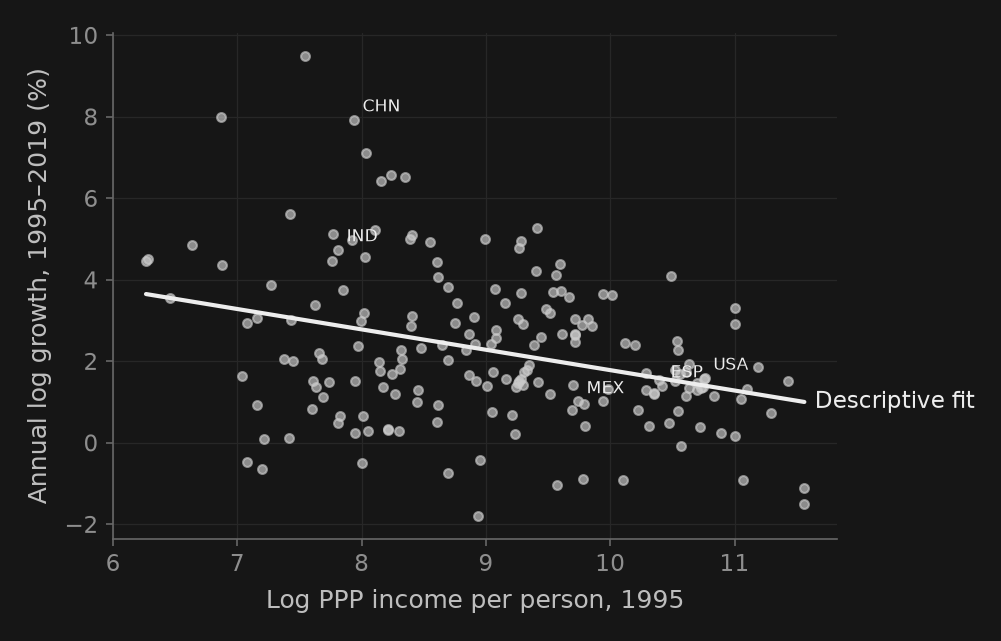

In [4]:
rows, excluded = [], []
for country, frame in a.groupby(level="code"):
    d = frame.droplevel("code")
    block = regular_block(d, ["gdp_pc"], freq="Y", start=START, end=END, min_obs=25)
    ppp0 = d.gdp_pc_ppp.get(pd.Timestamp(START), np.nan)
    if block is None or not np.isfinite(ppp0) or ppp0 <= 0:
        excluded.append(country); continue
    years = block.index[-1].year-block.index[0].year
    if not (block.gdp_pc > 0).all():
        excluded.append(country); continue
    growth = 100*np.log(block.gdp_pc.iloc[-1]/block.gdp_pc.iloc[0])/years
    rows.append({"code":country,"initial_ppp":ppp0,"growth_log_pct":growth,"n_years":len(block)})
growth_facts=pd.DataFrame(rows).set_index("code")
X=np.column_stack([np.ones(len(growth_facts)),np.log(growth_facts.initial_ppp)])
beta=np.linalg.lstsq(X,growth_facts.growth_log_pct,rcond=None)[0]
print(tr("Comparable annual sample:", "Muestra anual comparable:"),len(growth_facts))
print(tr("Excluded:", "Excluidos:"),", ".join(excluded))
print(tr("Descriptive slope on initial log PPP income:", "Pendiente descriptiva sobre ingreso PPA inicial:"),round(beta[1],3))
display(growth_facts.growth_log_pct.describe(percentiles=[.1,.5,.9]).round(2).to_frame())
fig, ax=_nbstyle.figura(1,1)
ax.scatter(np.log(growth_facts.initial_ppp),growth_facts.growth_log_pct,color=cols[1],s=18,alpha=.65)
xline=np.linspace(X[:,1].min(),X[:,1].max(),100)
ax.plot(xline,beta[0]+beta[1]*xline,color=cols[0],label=tr("Descriptive fit", "Ajuste descriptivo"))
for c in ["MEX","USA","CHN","IND","ESP"]:
    if c in growth_facts.index:
        ax.annotate(c,(np.log(growth_facts.loc[c,"initial_ppp"]),growth_facts.loc[c,"growth_log_pct"]),xytext=(4,4),textcoords="offset points",fontsize=8)
ax.set_xlabel(tr("Log PPP income per person, 1995", "Log ingreso PPA por persona, 1995"))
ax.set_ylabel(tr("Annual log growth, 1995–2019 (%)", "Crecimiento log anual, 1995–2019 (%)"))
_nbstyle.etiquetar(ax);plt.show()

**Read the figure.** Begin with the dispersion of growth rates and the countries excluded by the fixed window. The fitted slope is one descriptive feature, not a universal convergence law. Changes in PPP benchmarks and GDP revisions can move this picture even with the dates held fixed. The next exercise contrasts within-country time patterns with a cross section of levels.

## 2. Kaldor facts are hypotheses about time paths

A roughly stable capital-output ratio and factor shares, together with rising output per worker, motivate balanced growth. They do **not** imply that every country shares one $K/Y$ or one labour share.

Use PWT's `cn/cgdpo` at current PPPs for the 2019 cross section and `rnna/rgdpna` at constant national prices for within-country change. These measure stocks divided by annual output (**years**); `csh_i` is investment/output and `rkna` a capital-services index. Labour shares in PWT include the source's estimation and imputation assumptions. We do not replace missing observations with representative values.

Source: Feenstra, Inklaar and Timmer (2015), *The Next Generation of the Penn World Table*, [PWT 11.0](https://www.rug.nl/ggdc/productivity/pwt/), [data DOI](https://doi.org/10.34894/FABVLR).

,ky_ppp,labsh
count,180.00,140.00
mean,4.46,0.50
std,2.21,0.12
min,0.64,0.08
10%,2.18,0.33
50%,4.19,0.52
90%,6.74,0.64
max,14.69,0.75


,n,ky_annual_log_change,labour_share_change_pp,output_worker_annual_log_growth
count,139.0,139.00,139.00,139.00
mean,25.0,0.19,-2.56,1.90
std,0.0,1.87,8.32,1.87
min,25.0,-7.12,-35.65,-4.99
10%,25.0,-2.13,-14.15,0.01
50%,25.0,0.18,-0.91,1.77
90%,25.0,2.52,6.59,4.43
max,25.0,7.42,16.50,8.11


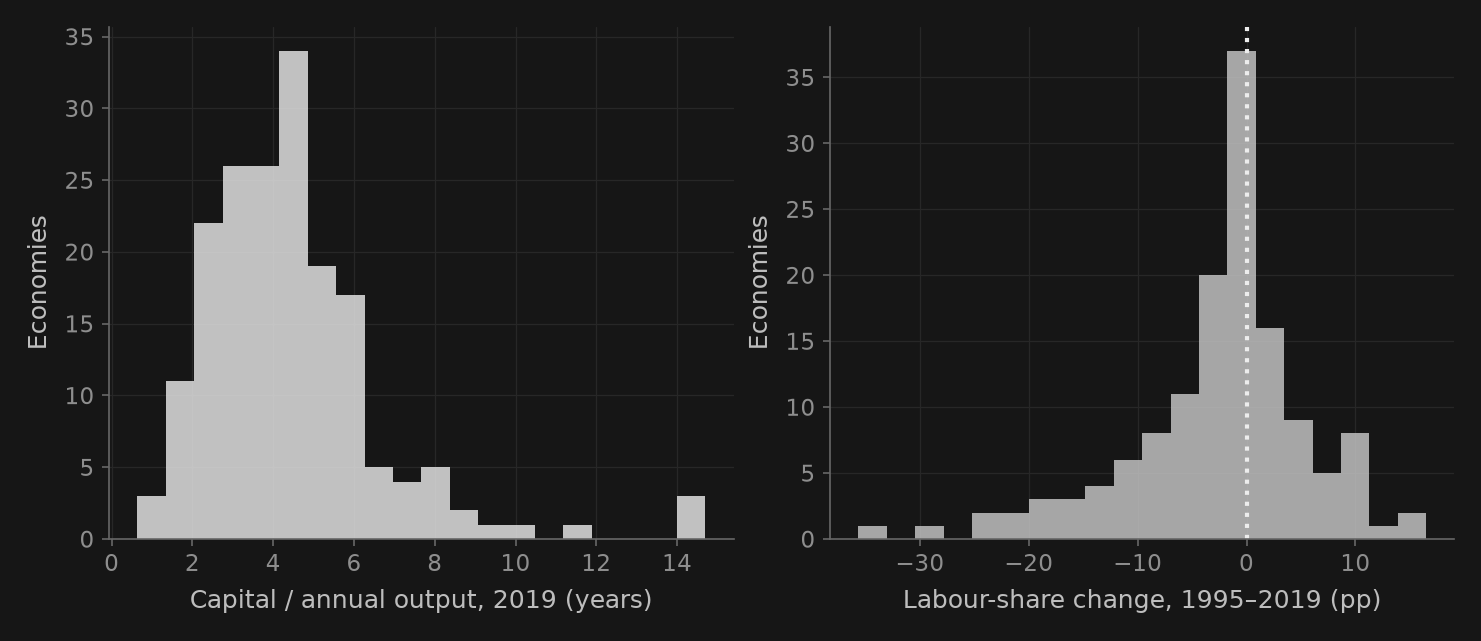

In [5]:
pwt["ky_national"] = pwt.rnna/pwt.rgdpna
pwt["ky_ppp"] = pwt.cn/pwt.cgdpo
pwt["output_per_worker"] = pwt.rgdpna/pwt.emp
cross = pwt.xs(pd.Timestamp("2019-01-01"), level="date")[["ky_ppp","labsh"]]
rows=[]
for c,d in pwt.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["ky_national","labsh","output_per_worker"],freq="Y",start=START,end=END,min_obs=25)
    if b is None or (b[["ky_national","output_per_worker"]] <= 0).any().any():
        continue
    rows.append({"code":c,"n":len(b),"ky_annual_log_change":100*np.log(b.ky_national.iloc[-1]/b.ky_national.iloc[0])/24,
                 "labour_share_change_pp":100*(b.labsh.iloc[-1]-b.labsh.iloc[0]),
                 "output_worker_annual_log_growth":100*np.log(b.output_per_worker.iloc[-1]/b.output_per_worker.iloc[0])/24})
kaldor=pd.DataFrame(rows).set_index("code")
display(cross.describe(percentiles=[.1,.5,.9]).round(2))
display(kaldor.describe(percentiles=[.1,.5,.9]).round(2))
fig, axes=_nbstyle.figura(1,2)
axes[0].hist(cross.ky_ppp.dropna(),bins=20,color=cols[0],alpha=.8)
axes[0].set_xlabel(tr("Capital / annual output, 2019 (years)","Capital / producto anual, 2019 (años)"))
axes[1].hist(kaldor.labour_share_change_pp,bins=20,color=cols[1],alpha=.8)
axes[1].axvline(0,color=cols[0],ls=":")
axes[1].set_xlabel(tr("Labour-share change, 1995–2019 (pp)","Cambio de participación laboral, 1995–2019 (pp)"))
for ax in axes:ax.set_ylabel(tr("Economies", "Economías"))
plt.show()

### 2.1 Why the labour share depends on whom we count

The raw national-accounts ratio is employee compensation over value added. A Gollin-style correction imputes to the self-employed the same average labour compensation as employees:
$$s_L^{raw}=\frac{W_E}{VA},\qquad s_L^{adj}=s_L^{raw}\frac{E}{E_E}.$$
This is an assumption about labour income, not an accounting identity. Use the same country-quarter for compensation, value added and employment. Values above one are a reason to examine definitions, not to clip the estimate silently. The detailed companion retains the richer informal-employment correction and the overlap between informality and self-employment.

,first,last,n,raw_pct,adjusted_pct,quarters_above_one
code,,,,,,
MEX,2008Q1,2019Q4,48,26.67,39.64,0
GRC,1995Q1,2019Q4,100,38.23,58.40,0
ROU,1995Q1,2019Q4,100,39.79,61.18,0
SRB,1995Q1,2019Q4,100,40.20,65.99,0
BGR,1995Q1,2019Q4,100,41.51,56.65,0
IRL,1995Q1,2019Q4,100,42.41,51.35,0
ITA,1995Q1,2019Q4,100,42.92,58.98,0
SVK,1995Q1,2019Q4,100,43.28,49.60,0
POL,1995Q1,2019Q4,100,44.26,58.79,0


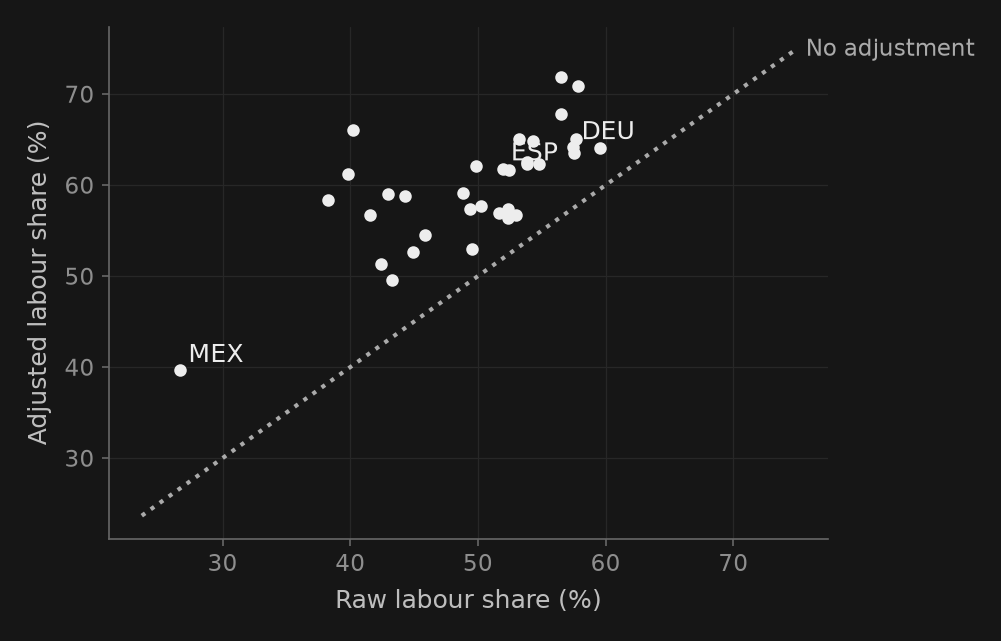

In [6]:
rows=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["comp_emp","va_total","emp","emp_employees"],start=START,end=END,min_obs=40)
    if b is None or (b[["va_total","emp_employees"]]<=0).any().any():continue
    raw=b.comp_emp/b.va_total
    adjusted=raw*b.emp/b.emp_employees
    rows.append({"code":c,"first":b.index.min().to_period("Q"),"last":b.index.max().to_period("Q"),
                 "n":len(b),"raw_pct":100*raw.mean(),"adjusted_pct":100*adjusted.mean(),
                 "quarters_above_one":int((adjusted>1).sum())})
shares=pd.DataFrame(rows).set_index("code")
display(shares.sort_values("raw_pct").round({col:2 for col in shares.sort_values("raw_pct").select_dtypes("number")}))
fig,ax=_nbstyle.figura(1,1)
ax.scatter(shares.raw_pct,shares.adjusted_pct,color=cols[0],s=25)
limits=[min(shares.raw_pct.min(),shares.adjusted_pct.min())-3,max(shares.raw_pct.max(),shares.adjusted_pct.max())+3]
ax.plot(limits,limits,color=cols[2],ls=":",label=tr("No adjustment", "Sin ajuste"))
for c in ["MEX","ESP","DEU","CHL"]:
    if c in shares.index:ax.annotate(c,(shares.loc[c,"raw_pct"],shares.loc[c,"adjusted_pct"]),xytext=(4,4),textcoords="offset points")
ax.set_xlabel(tr("Raw labour share (%)","Participación bruta (%)"))
ax.set_ylabel(tr("Adjusted labour share (%)","Participación ajustada (%)"))
_nbstyle.etiquetar(ax);plt.show()

### 2.2 Relative investment prices: equipment is not structures

The ratio $P_{eq}/P_C$ can trend differently from $P_{st}/P_C$. Compute annualized log changes within each country on a common sample, not cross-country ratios of arbitrarily based deflator levels. The consumption deflator here includes durables; the companion's more detailed measurement subtracts that margin and compares durable consumption directly with equipment investment.

In [7]:
prices=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["inv_equip_defl","inv_struct_defl","cons_hh_defl"],start=START,end=END,min_obs=40)
    if b is None or (b<=0).any().any():continue
    relative=b[["inv_equip_defl","inv_struct_defl"]].div(b.cons_hh_defl,axis=0)
    trend=400*np.log(relative).diff().mean()
    prices.append({"code":c,"first":b.index.min().to_period("Q"),"last":b.index.max().to_period("Q"),"n":len(b),
                   "equipment_relative_price_growth":trend.inv_equip_defl,
                   "structures_relative_price_growth":trend.inv_struct_defl})
price_facts=pd.DataFrame(prices).set_index("code")
display(price_facts.round({col:2 for col in price_facts.select_dtypes("number")}))

,first,last,n,equipment_relative_price_growth,structures_relative_price_growth
code,,,,,
AUS,1995Q1,2019Q4,100,-3.53,0.70
AUT,1995Q1,2019Q4,100,-0.78,0.65
BGR,1996Q1,2019Q4,96,1.57,5.56
BIH,2000Q1,2019Q4,80,-2.89,0.61
CAN,1995Q1,2019Q4,100,-2.13,1.50
CHL,1996Q1,2019Q4,96,-2.84,-0.24
CRI,1995Q1,2019Q4,100,-0.91,-0.07
CYP,1996Q1,2010Q4,60,-0.99,0.91
CZE,1995Q1,2019Q4,100,-3.14,1.12


## 3. Short run: define the moment before calculating it

For each country-variable pair, retain the longest **contiguous common sample** within 1995–2019 (at least 60 quarters). Filter both series on those same observations. When comparing HP, Hamilton and first differences, evaluate all methods on their shared valid dates. This avoids giving one filter a longer pandemic-free history than another.

For a transformed variable $x$ and output $y$, report
$$\frac{\sigma(x)}{\sigma(y)},\qquad \operatorname{corr}(x,y),\qquad \operatorname{corr}(x_t,x_{t-1}).$$
Growth-rate moments remain growth-rate moments; they are a robustness comparison, not a second output-gap definition. Consumption is household consumption including durables; `inv` is gross fixed capital formation. The labour extension uses total hours, employment, productivity $Y/H$ and hours per worker $H/E$ on their own reported samples.

In [8]:
q["productivity"] = q.gdp_real/q.hours
q["hours_per_worker"] = q.hours/q.emp
VARIABLES={"consumption":"cons_hh_real","investment":"inv_real","hours":"hours",
           "employment":"emp","productivity":"productivity","hours_per_worker":"hours_per_worker"}

def transformations(s):
    return pd.DataFrame({"HP":np.asarray(hp_filter(s,lamb=1600)[0]),
                         "Hamilton":np.asarray(hamilton_filter(s,h=8,p=4)[0]),
                         "growth":s.diff().to_numpy()},index=s.index)

rows=[]
for c,d in q.groupby(level="code"):
    for label,var in VARIABLES.items():
        b=regular_block(d.droplevel("code"),["gdp_real",var],start=START,end=END,min_obs=60)
        if b is None or (b<=0).any().any():continue
        y=transformations(100*np.log(b.gdp_real))
        x=transformations(100*np.log(b[var]))
        valid=y.notna().all(axis=1)&x.notna().all(axis=1)
        for method in y.columns:
            yy,xx=y.loc[valid,method],x.loc[valid,method]
            rows.append({"code":c,"variable":label,"method":method,
                         "input_first":b.index[0].to_period("Q"),"input_last":b.index[-1].to_period("Q"),
                         "n_input":len(b),"n":len(yy),"sd_ratio":xx.std()/yy.std(),
                         "corr_y":xx.corr(yy),"rho1":xx.autocorr()})
moments=pd.DataFrame(rows)
display(moments.groupby(["variable","method"]).agg(countries=("code","nunique"),
    median_sd_ratio=("sd_ratio","median"),median_corr_y=("corr_y","median"),median_rho1=("rho1","median")).round(2))
# Every comparison across methods really uses the same country-pair dates.
assert moments.groupby(["code","variable"])["n"].nunique().eq(1).all()

countries  median_sd_ratio  median_corr_y  \
variable         method                                                
consumption      HP               53             1.04           0.69   
                 Hamilton         53             1.05           0.73   
                 growth           53             1.00           0.48   
employment       HP               37             0.57           0.53   
                 Hamilton         37             0.57           0.61   
                 growth           37             0.54           0.32   
hours            HP               35             0.80           0.61   
                 Hamilton         35             0.74           0.63   
                 growth           35             0.94           0.30   
hours_per_worker HP               34             0.44           0.22   
                 Hamilton         34             0.34           0.21   
                 growth           34             0.73           0.10   
investment       HP               55             3.29           0.72   
                 Hamilton         55             2.97           0.75   
                 growth           55             3.53           0.47   
productivity     HP               35             0.81           0.64   
                 Hamilton         35             0.66           0.63   
                 growth           35             1.11           0.63   

                           median_rho1  
variable         method                 
consumption      HP               0.79  
                 Hamilton         0.87  
                 growth           0.22  
employment       HP               0.89  
                 Hamilton         0.87  
                 growth           0.42  
hours            HP               0.79  
                 Hamilton         0.84  
                 growth          -0.08  
hours_per_worker HP               0.37  
                 Hamilton         0.70  
                 growth          -0.33  
investment       HP               0.77  
                 Hamilton         0.86  
                 growth          -0.01  
productivity     HP               0.60  
                 Hamilton         0.81  
                 growth          -0.18

**Read the distribution, not only its median.** The core questions are whether investment is more volatile than output, whether consumption is smoother, and whether measured productivity is procyclical. Report how many countries support each statement and how many change sign or cross a threshold under another transformation. A common “stylized fact” may describe most countries and fail in a meaningful minority. Comparing marginal medians from different country samples does not identify a labour-margin decomposition.

,countries,above_under_all,below_under_all,changes_verdict
variable,,,,
consumption,53,20,16,17
investment,55,55,0,0
productivity,35,33,1,1


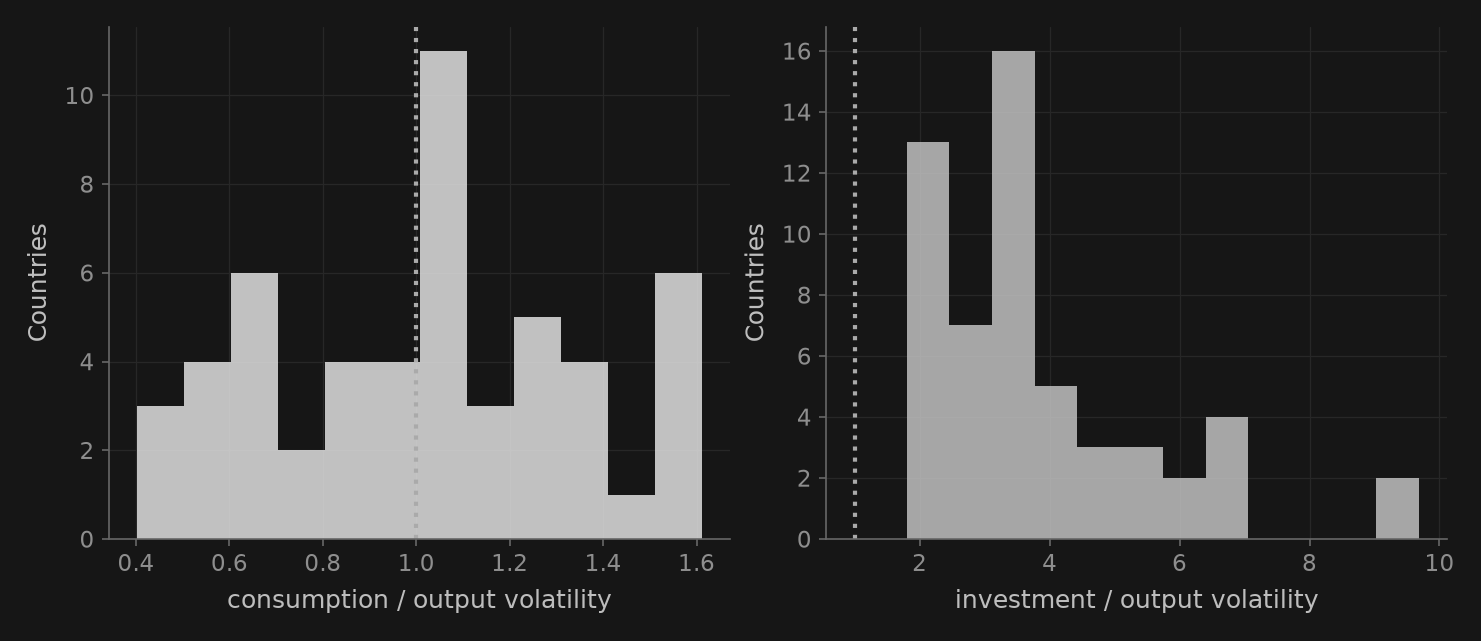

In [9]:
verdict=[]
for var in ["consumption","investment","productivity"]:
    metric="corr_y" if var=="productivity" else "sd_ratio"
    threshold=0 if var=="productivity" else 1
    table=moments.loc[moments.variable==var].pivot(index="code",columns="method",values=metric).dropna()
    positive=table.gt(threshold)
    verdict.append({"variable":var,"countries":len(table),"above_under_all":int(positive.all(axis=1).sum()),
                    "below_under_all":int((~positive).all(axis=1).sum()),
                    "changes_verdict":int(positive.nunique(axis=1).gt(1).sum())})
display(pd.DataFrame(verdict).set_index("variable"))
fig,axes=_nbstyle.figura(1,2)
for j,var in enumerate(["consumption","investment"]):
    vals=moments.query("variable == @var and method == 'HP'").sd_ratio
    axes[j].hist(vals,bins=12,color=cols[j],alpha=.8)
    axes[j].axvline(1,color=cols[2],ls=":")
    axes[j].set_xlabel(tr(var+" / output volatility", {"consumption":"Volatilidad consumo / producto","investment":"Volatilidad inversión / producto"}[var]))
    axes[j].set_ylabel(tr("Countries", "Países"))
plt.show()

### 3.1 Persistence and the business-cycle band

The conventional 6–32-quarter band corresponds to roughly 1.5–8 years. Measure the share of HP-cycle power inside that band with a common Welch segment length of 64 quarters. Shorter series are excluded and counted; changing the segment length by country would change frequency resolution. This is concentration of a **filtered** series, not proof that the unfiltered economy has a deterministic periodic cycle.

In [10]:
spectral_rows=[];spectral_excluded=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["gdp_real"],start=START,end=END,min_obs=64)
    if b is None or (b.gdp_real<=0).any():spectral_excluded.append(c);continue
    cycle=pd.Series(np.asarray(hp_filter(100*np.log(b.gdp_real),lamb=1600)[0]),index=b.index)
    spectral_rows.append({"code":c,"n":len(cycle),"first":b.index[0].to_period("Q"),
                          "last":b.index[-1].to_period("Q"),"sd_y":cycle.std(),"rho1_y":cycle.autocorr(),
                          "power_6_32":float(business_cycle_band_power(cycle.to_numpy(),n_seg=64))})
spectral=pd.DataFrame(spectral_rows).set_index("code")
display(spectral.round({col:3 for col in spectral.select_dtypes("number")}))
print(tr("Insufficient continuous GDP history:", "Historia continua de PIB insuficiente:"),spectral_excluded)

,n,first,last,sd_y,rho1_y,power_6_32
code,,,,,,
ALB,96,1996Q1,2019Q4,3.056,0.696,0.544
ARG,64,2004Q1,2019Q4,2.763,0.794,0.918
AUS,100,1995Q1,2019Q4,0.555,0.600,0.817
AUT,100,1995Q1,2019Q4,1.152,0.860,0.898
BEL,100,1995Q1,2019Q4,0.910,0.859,0.915
BGR,96,1996Q1,2019Q4,2.660,0.636,0.597
BIH,80,2000Q1,2019Q4,1.471,0.631,0.599
BRA,96,1996Q1,2019Q4,1.655,0.781,0.771
CAN,100,1995Q1,2019Q4,1.058,0.858,0.892


Insufficient continuous GDP history: ['ARM', 'CHN', 'CMR', 'COL', 'IND', 'KEN', 'KGZ', 'LSO', 'MAR', 'MDA', 'MNE', 'SAU', 'UGA']


### 3.2 Include the pandemic, then explain what changed

The 1995–2019 baseline defines a pre-pandemic descriptive sample; it does not make 2020 irrelevant or “not macroeconomics.” Compare the consumption/output volatility ratio on exactly the same countries with complete 1995–2024 data. Here we use **growth rates** so that adding years does not revise an HP trend over the earlier window. This changes the set of episodes, including both the pandemic and recovery; it is not a causal estimate of the pandemic alone.

In [11]:
sensitivity=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["gdp_real","cons_hh_real"],start="1995",end="2024",min_obs=120)
    if b is None or (b<=0).any().any():continue
    g=100*np.log(b).diff().dropna()
    old=g.loc[:"2019"]
    sensitivity.append({"code":c,"n_pre":len(old),"n_full":len(g),
                        "pre_2020":old.cons_hh_real.std()/old.gdp_real.std(),
                        "through_2024":g.cons_hh_real.std()/g.gdp_real.std()})
sensitivity=pd.DataFrame(sensitivity).set_index("code")
sensitivity["change"]=sensitivity.through_2024-sensitivity.pre_2020
display(sensitivity.sort_values("change").round(3))

,n_pre,n_full,pre_2020,through_2024,change
code,,,,,
HUN,99,119,1.517,0.928,-0.589
ESP,99,119,1.576,1.265,-0.311
PRT,99,119,1.224,1.087,-0.137
HRV,99,119,1.191,1.067,-0.124
ZAF,99,119,1.303,1.225,-0.078
GBR,99,119,1.257,1.200,-0.057
GRC,99,119,0.987,0.946,-0.041
ROU,99,119,1.589,1.559,-0.030
FRA,99,119,1.025,1.018,-0.007


## 4. Recession anatomy: one identity, three margins

Use the same scope for output $Y$, hours $H$ and employment $E$:
$$Y=\frac{Y}{H}\frac{H}{E}E,\qquad \Delta\log Y=\Delta\log(Y/H)+\Delta\log(H/E)+\Delta\log E.$$
The identity partitions an observed change; it does not identify technology, preferences or policy shocks. A rise in measured productivity during job losses may reflect composition. The exercise below compares **fixed common windows** (2008Q1–2009Q2 and 2019Q4–2020Q2), not each country's individually dated peak and trough. The labour companion retains country-specific dating and the broader Okun–Beveridge–Phillips evidence.

,code,episode,output,productivity,hours_per_worker,employment
0,AUT,GFC,-5.04,-2.39,-2.27,-0.38
1,AUT,COVID,-15.14,4.62,-15.26,-4.50
2,BEL,GFC,-3.54,-1.89,-1.97,0.32
3,BEL,COVID,-14.18,5.99,-19.02,-1.15
4,BGR,GFC,-1.65,2.46,-4.61,0.50
...,...,...,...,...,...,...
68,SVK,COVID,-10.34,9.01,-17.24,-2.10
69,SVN,GFC,-8.81,-6.92,-1.34,-0.54
70,SVN,COVID,-12.82,2.68,-13.87,-1.62
71,SWE,GFC,-6.09,-2.81,-1.15,-2.12


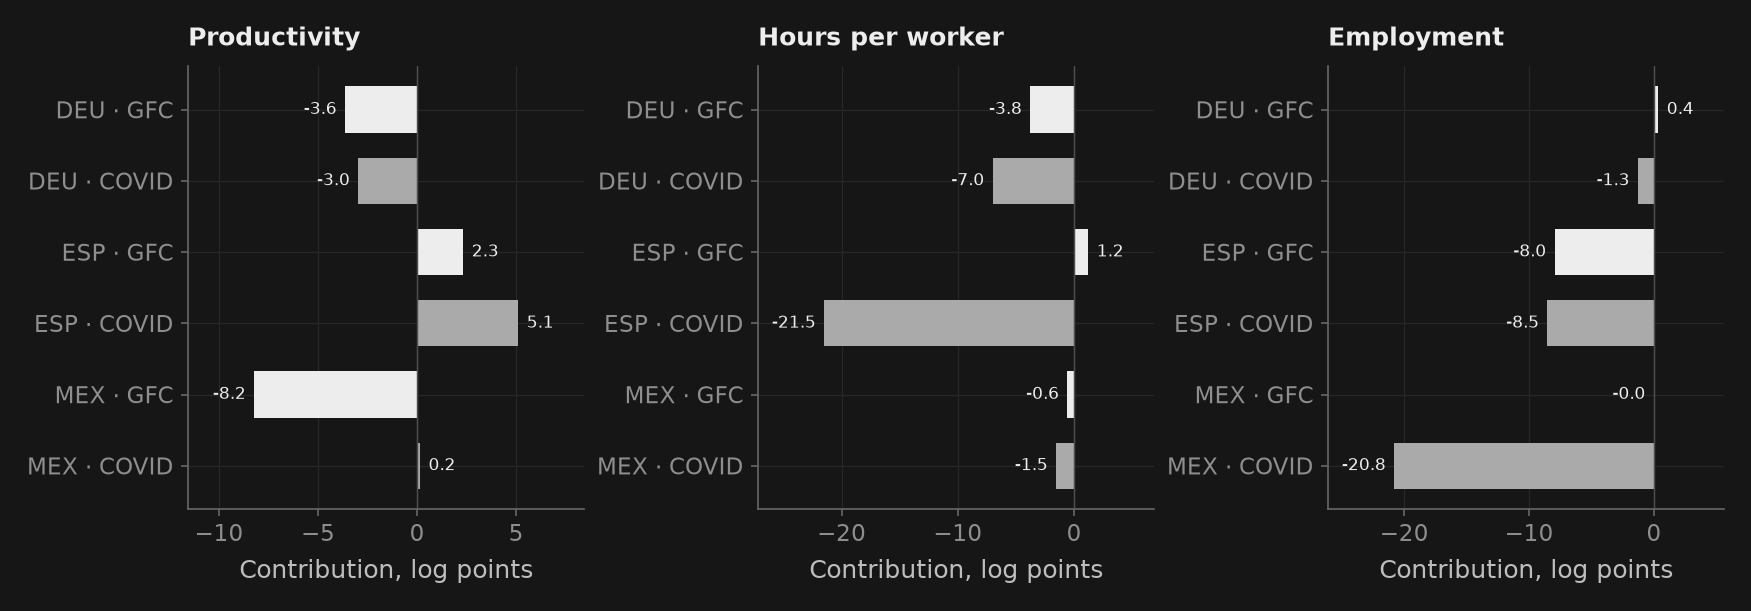

In [12]:
episodes={"GFC":("2008-01-01","2009-04-01"),"COVID":("2019-10-01","2020-04-01")}
rows=[]
for c,d in q.groupby(level="code"):
    d=d.droplevel("code")
    for episode,(start,end) in episodes.items():
        b=d.reindex(pd.to_datetime([start,end]))[["gdp_real","hours","emp"]]
        if b.isna().any().any() or (b<=0).any().any():continue
        changes=100*np.log(b.iloc[1]/b.iloc[0])
        rows.append({"code":c,"episode":episode,"output":changes.gdp_real,
                     "productivity":changes.gdp_real-changes.hours,
                     "hours_per_worker":changes.hours-changes.emp,"employment":changes.emp})
anatomy=pd.DataFrame(rows)
anatomy["residual"]=anatomy.output-anatomy.productivity-anatomy.hours_per_worker-anatomy.employment
assert anatomy.residual.abs().max()<1e-10
display(anatomy.drop(columns="residual").round(2))
fig,axes=_nbstyle.figura(1,3)
selected=["DEU","ESP","MEX"]
b=anatomy.set_index(["code","episode"]).reindex(pd.MultiIndex.from_product([selected,episodes])).dropna()
labels=[f"{c} · {e}" for c,e in b.index]
colors=[cols[0] if e=="GFC" else cols[2] for c,e in b.index]
for ax,var,title in zip(axes,["productivity","hours_per_worker","employment"],
        [tr("Productivity","Productividad"),tr("Hours per worker","Horas por trabajador"),tr("Employment","Empleo")]):
    y=np.arange(len(b))
    bars=ax.barh(y,b[var],color=colors,height=.65)
    ax.set_yticks(y,labels);ax.invert_yaxis()
    ax.bar_label(bars,fmt="%.1f",padding=4,fontsize=8)
    ax.axvline(0,color=cols[-1],lw=.7)
    ax.set_title(title)
    ax.set_xlabel(tr("Contribution, log points", "Contribución, puntos log"))
    ax.margins(x=.25)
plt.show()

### 4.1 Okun is a reduced form, not a structural constant

Relate the unemployment gap to the output gap on the same sample:
$$u_t-\tau^u_t=\alpha+\beta(y_t-\tau^y_t)+\varepsilon_t.$$
A negative $\beta$ summarizes comovement conditional on definitions, sample and filters. It does not identify the causal effect of an output intervention on unemployment. The Beveridge relation describes vacancies and unemployment; the Phillips relation describes prices and slack. Their parameters can change with institutions, expectations, composition and policy.

The [labour companion, §5](T01_A_business_cycle_facts.ipynb) preserves the detailed three-curve analysis, labour-margin evidence and recession experiments. The [frequency companion](T01_C_high_frequency.ipynb) retains worker flows, matching and interstate adjustment. Study those after the core facts; monetary-policy identification belongs with the later empirical modules.

In [13]:
okun_rows=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["gdp_real","urate"],start=START,end=END,min_obs=60)
    if b is None or (b.gdp_real<=0).any():continue
    yg=np.asarray(hp_filter(100*np.log(b.gdp_real),lamb=1600)[0])
    ug=np.asarray(hp_filter(b.urate,lamb=1600)[0])
    X=np.column_stack([np.ones(len(b)),yg])
    fit=np.linalg.lstsq(X,ug,rcond=None)[0]
    okun_rows.append({"code":c,"first":b.index[0].to_period("Q"),"last":b.index[-1].to_period("Q"),
                      "n":len(b),"beta_descriptive":fit[1],"corr":np.corrcoef(yg,ug)[0,1]})
okun=pd.DataFrame(okun_rows).set_index("code")
display(okun.sort_values("beta_descriptive").round({col:3 for col in okun.sort_values("beta_descriptive").select_dtypes("number")}))
print(tr("Negative slopes / estimated countries:", "Pendientes negativas / países estimados:"),
      int(okun.beta_descriptive.lt(0).sum()), "/",len(okun))

,first,last,n,beta_descriptive,corr
code,,,,,
ESP,1995Q1,2019Q4,100,-0.912,-0.895
USA,1995Q1,2019Q4,100,-0.585,-0.864
BGR,2000Q1,2019Q4,80,-0.517,-0.588
GRC,1998Q2,2019Q4,87,-0.499,-0.801
PRT,1995Q1,2019Q4,100,-0.497,-0.725
POL,1997Q1,2019Q4,92,-0.495,-0.462
LTU,1998Q1,2019Q4,88,-0.477,-0.876
EST,1997Q1,2019Q4,92,-0.400,-0.799
LVA,1998Q2,2019Q4,87,-0.399,-0.895


Negative slopes / estimated countries: 39 / 39


## 5. From facts to model targets

| Evidence | What a model must explain | What the table does not establish |
|---|---|---|
| Growth dispersion and capital/output paths | Accumulation, productivity and heterogeneity | A causal return to capital from a cross section |
| Raw and adjusted labour shares | Labour income, self-employment and sector definitions | One technology parameter common to every country |
| Relative volatility and comovement | Consumption smoothing, investment and labour adjustment | Identified structural shocks |
| Recession decompositions | Different extensive/intensive margins | Technology shocks from measured productivity alone |
| Output-gap revisions and cycle signals (B) | The policymaker's imperfect information | An observed, model-free potential output |

A useful target has five attributes: **concept, frequency, sample, transformation and vintage**. Those attributes travel with the number. Filtering the data and model differently, or calibrating to a selected country while describing the result as global, changes the exercise.

## 6. Your turn

1. **Long run:** compare the 2019 cross-country dispersion of $K/Y$ with 1995–2019 changes within countries. Which version of “constant capital/output” does each address?
2. **Short run:** select a country where consumption's relative volatility crosses one across transformations. Hold the common dates fixed and explain what changes.
3. **Measurement:** compare PWT labour shares with the raw and adjusted QNA shares. Do not attribute their differences to one cause until denominators, sectors, self-employment and dates match.
4. **Recession:** change the fixed GFC window to country-specific peaks and troughs, using the dating procedure from the companion. Report countries whose employment/productivity interpretation changes.
5. **Model discipline:** choose three robust moments and write a target table with the five attributes above. Reserve causal policy questions for the later identification module.

### Solutions (outline)
Cross-country equality and within-country stability are different restrictions. First differences emphasize growth innovations while HP and Hamilton extract different lower-frequency components. PWT and QNA labour shares need not measure the same denominator or imputation. Recession dates alter the identity's endpoints but never its exact arithmetic. A model should face the same observation and filtering procedure as the data.

### Explore with AI
Ask the tutor to challenge a proposed calibration target: require a sensitivity check and an explicit distinction between an accounting identity, a descriptive correlation and an identifying assumption.

**Next in the course:** growth and dynamic models in Module 2. The detailed national-accounts, labour and high-frequency notebooks remain optional companions. Their causal applications provide later bridges to Modules 3, 5 and 8.